# Analysis on the Atlas Higgs Boson Machine Learning Challenge

## Necessary package installer

In [3]:
# Install packages if not already installed
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [4]:
%matplotlib inline
%load_ext autoreload
%autoreload 2 

# Third party
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import train_test_split

# Local package
from src.import_data import Dataloader
import src.higgs_lgbm as h

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
loader = Dataloader()
loader.download_dataset() #Downloads the dataset if not already present
df = pd.read_csv(loader.CSV_PATH) #Creates dataframe from csv downloads csv automatically if not already present
#Check src.import_data for the Dataloader class and its CSV_PATH attribute

Dataset already exists at data\atlas-higgs-challenge-2014-v2.csv. Skipping download.


# Exploratory Data Analysis

Text(0.5, 1.0, 'Signal vs. Background event counts')

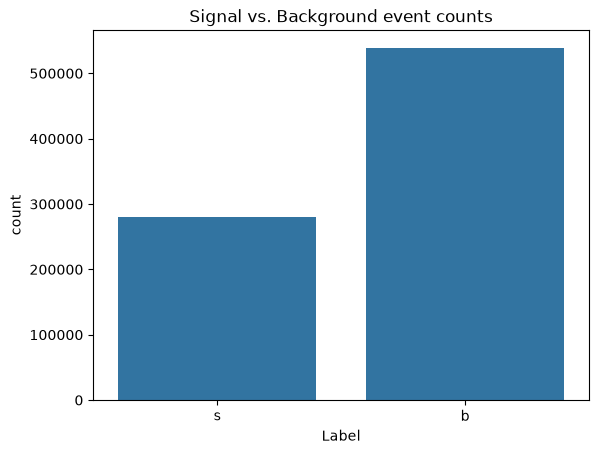

In [6]:
df['Label'].value_counts(normalize=True)
sns.countplot(data=df, x='Label') 
plt.title('Signal vs. Background event counts')

In [7]:
sentinel_counts = (df == -999.0).sum().sort_values(ascending=False)
sentinel_counts[sentinel_counts > 0]

DER_prodeta_jet_jet       580253
DER_deltaeta_jet_jet      580253
DER_mass_jet_jet          580253
PRI_jet_subleading_phi    580253
PRI_jet_subleading_pt     580253
PRI_jet_subleading_eta    580253
DER_lep_eta_centrality    580253
PRI_jet_leading_phi       327371
PRI_jet_leading_pt        327371
PRI_jet_leading_eta       327371
DER_mass_MMC              124602
dtype: int64

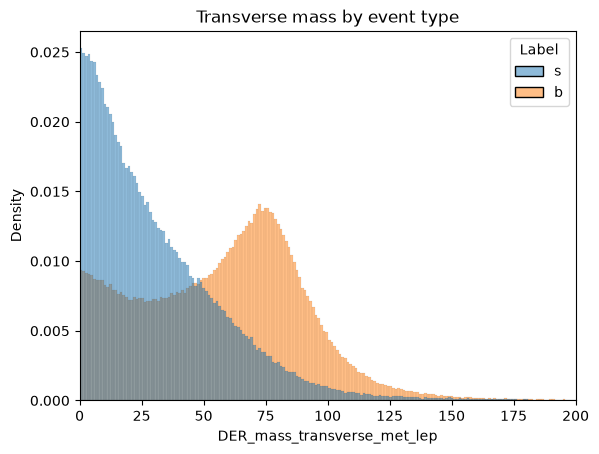

In [8]:
sns.histplot(
    data=df[df['DER_mass_transverse_met_lep'] != -999],
    x='DER_mass_transverse_met_lep',
    hue='Label',
    bins=900,
    stat='density',
    common_norm=False
)
plt.title('Transverse mass by event type')
plt.xlim(0, 200)  # Cap the x-axis at 200
plt.show()  # Optional: ensures the plot is displayed if not in interactive mode

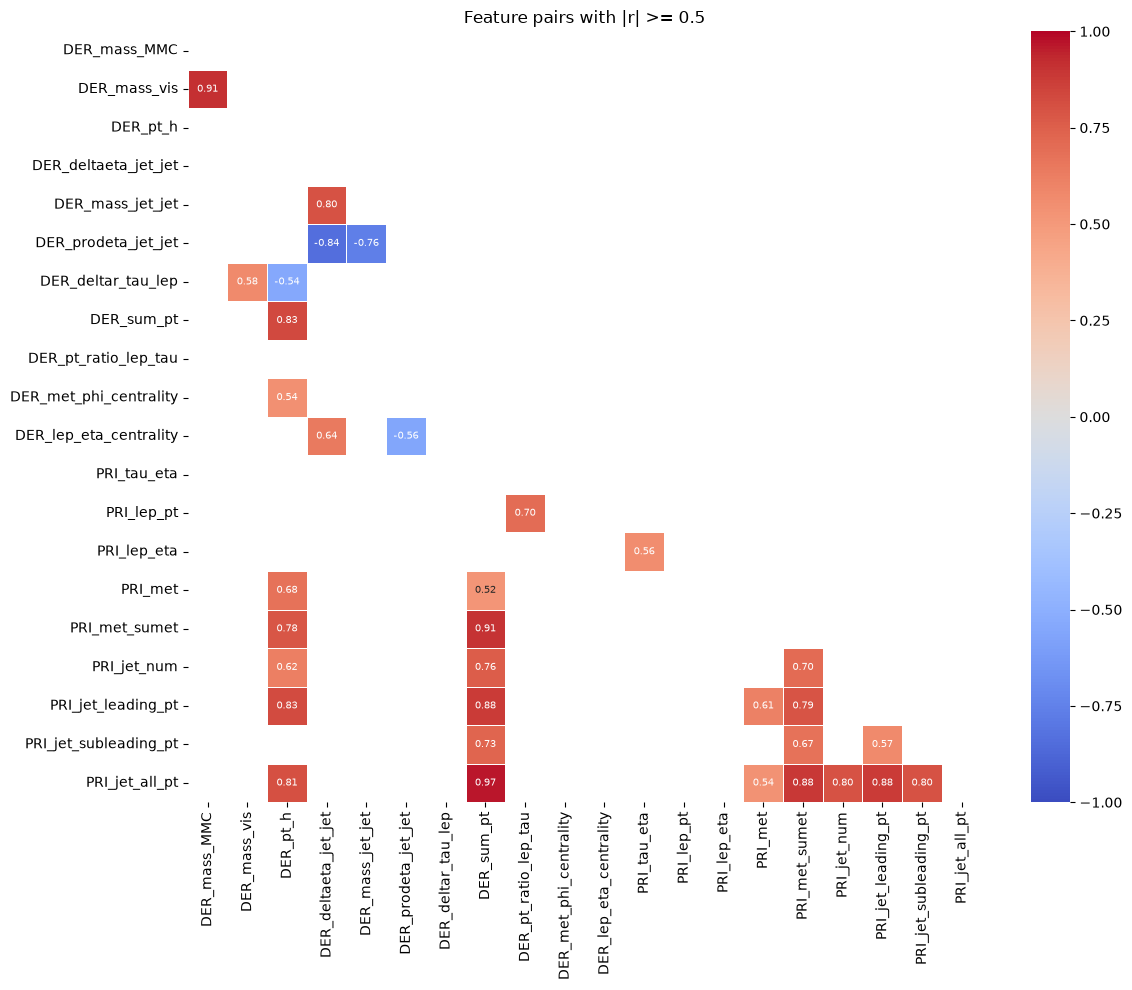

In [9]:
threshold = 0.5

numeric_cols = (df.select_dtypes(include='number')
                  .drop(columns=['Weight', 'KaggleWeight'], errors='ignore')
                  .replace(-999.0, np.nan))  # sentinel values distort correlations

corr = numeric_cols.corr()

# keep only features with at least one strong partner (ignoring self-correlation)
strong = (corr.abs() >= threshold) & ~np.eye(len(corr), dtype=bool)
keep = strong.any(axis=0)
corr_f = corr.loc[keep, keep]

# hide weak cells and the redundant upper triangle (including the diagonal)
mask = (corr_f.abs() < threshold) | np.triu(np.ones(corr_f.shape, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(corr_f, mask=mask, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.5)
plt.title(f'Feature pairs with |r| >= {threshold}')
plt.tight_layout()
plt.show()

# Train LightGBM

#### Create training data set and show basics I.E. head and describe

In [12]:

train_df = h.load_kaggle_training("data/atlas-higgs-challenge-2014-v2.csv")  # adjust to wherever Dataloader saves it

train_df.head()
train_df.info()
train_df.describe()
print(train_df.shape)
print(train_df["Label"].value_counts())
print("Total weight by class:")
print(train_df.groupby("Label")["Weight"].sum())

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 35 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   EventId                      250000 non-null  int64  
 1   DER_mass_MMC                 250000 non-null  float64
 2   DER_mass_transverse_met_lep  250000 non-null  float64
 3   DER_mass_vis                 250000 non-null  float64
 4   DER_pt_h                     250000 non-null  float64
 5   DER_deltaeta_jet_jet         250000 non-null  float64
 6   DER_mass_jet_jet             250000 non-null  float64
 7   DER_prodeta_jet_jet          250000 non-null  float64
 8   DER_deltar_tau_lep           250000 non-null  float64
 9   DER_pt_tot                   250000 non-null  float64
 10  DER_sum_pt                   250000 non-null  float64
 11  DER_pt_ratio_lep_tau         250000 non-null  float64
 12  DER_met_phi_centrality       250000 non-null  float64
 13  DER_lep_et

In [13]:
model, thr, val = h.train_lgbm(train_df)

Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.93108
[200]	valid_0's auc: 0.933393
[300]	valid_0's auc: 0.933878
[400]	valid_0's auc: 0.934059
[500]	valid_0's auc: 0.934046
Early stopping, best iteration is:
[428]	valid_0's auc: 0.934121
best iteration: 428, threshold: 0.940, AMS: 3.591, events selected: 14.9%


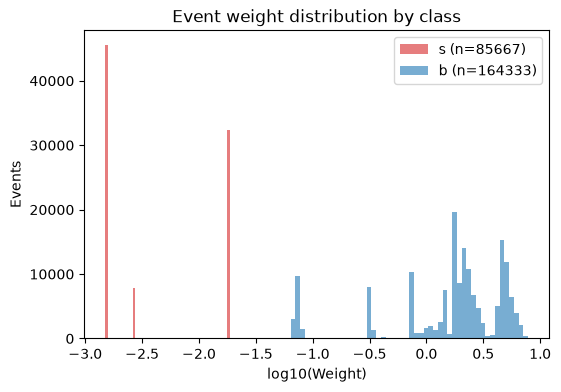

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
for lab, color in [("s", "tab:red"), ("b", "tab:blue")]:
    w = train_df.loc[train_df["Label"] == lab, "Weight"]
    ax.hist(np.log10(w), bins=50, alpha=0.6, label=f"{lab} (n={len(w)})", color=color)
ax.set_xlabel("log10(Weight)")
ax.set_ylabel("Events")
ax.set_title("Event weight distribution by class")
ax.legend()
plt.show()

#### ROC Curve output 

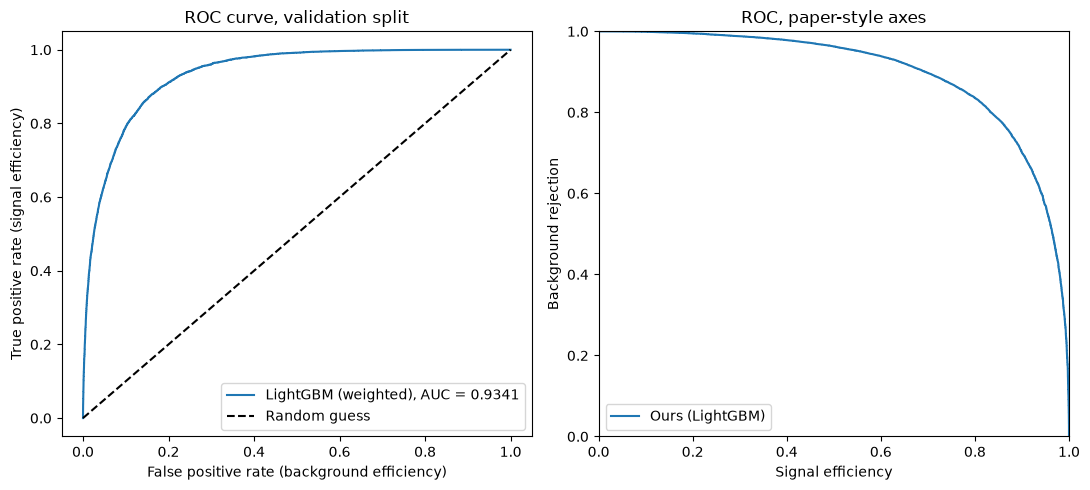

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
h.plot_roc(val, weighted=True, ax=axes[0])
h.plot_roc_paper_axes(val, weighted=False, ax=axes[1])
axes[1].set_title("ROC, paper-style axes")
plt.tight_layout()
plt.show()

#### Feature importance

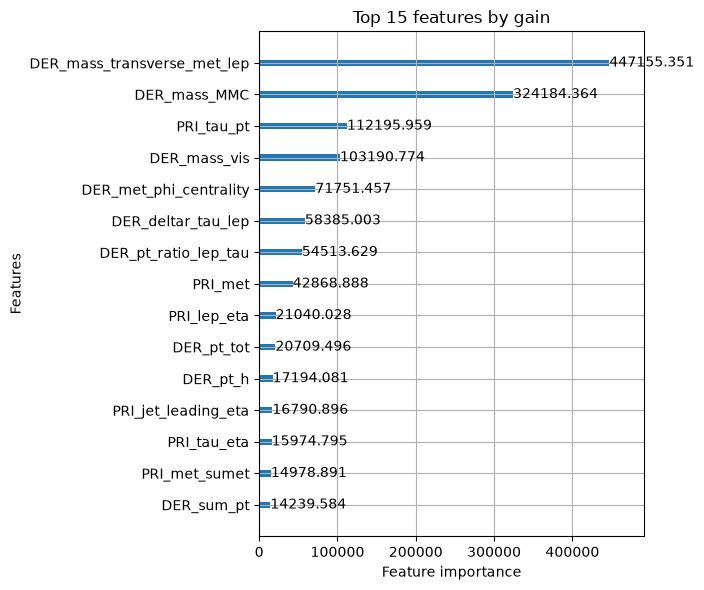

In [18]:
lgb.plot_importance(model, importance_type="gain", max_num_features=15, figsize=(7, 6))
plt.title("Top 15 features by gain")
plt.tight_layout()
plt.show()

#### Generate AMS Curve (Approximate median significance)

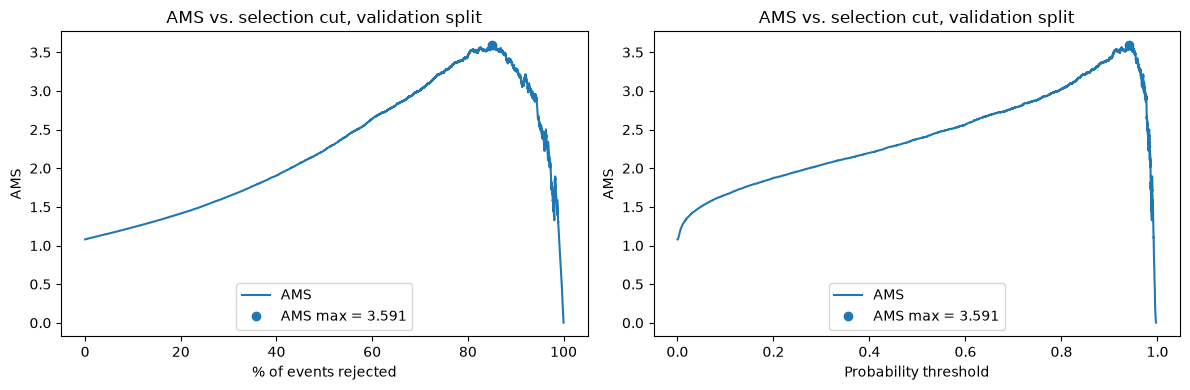

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
h.plot_ams_curve(val, x="rejected", ax=axes[0])    # like the paper's Fig. 10
h.plot_ams_curve(val, x="threshold", ax=axes[1])   # like the paper's Fig. 7b
plt.tight_layout()
plt.show()

#### AMS curves based off different splits of features

Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.926707
[200]	valid_0's auc: 0.928997
[300]	valid_0's auc: 0.929625
[400]	valid_0's auc: 0.929889
[500]	valid_0's auc: 0.930032
[600]	valid_0's auc: 0.93016
[700]	valid_0's auc: 0.930104
Early stopping, best iteration is:
[604]	valid_0's auc: 0.930169
best iteration: 604, threshold: 0.945, AMS: 3.478, events selected: 13.8%
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.879987
[200]	valid_0's auc: 0.891023
[300]	valid_0's auc: 0.897735
[400]	valid_0's auc: 0.9014
[500]	valid_0's auc: 0.903354
[600]	valid_0's auc: 0.904957
[700]	valid_0's auc: 0.906581
[800]	valid_0's auc: 0.907676
[900]	valid_0's auc: 0.908398
[1000]	valid_0's auc: 0.908988
[1100]	valid_0's auc: 0.909566
[1200]	valid_0's auc: 0.909841
[1300]	valid_0's auc: 0.910174
[1400]	valid_0's auc: 0.910573
[1500]	valid_0's auc: 0.910928
[1600]	valid_0's auc: 0.910988
Early stopping, best iteration is:
[1561]	v

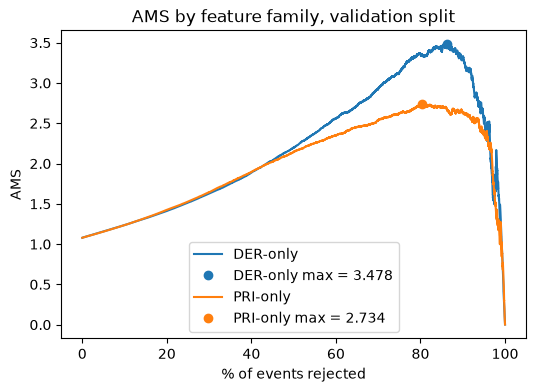

In [17]:
ams_by_group = {}
for feature_group in ("DER", "PRI"):
    _, _, ams_by_group[feature_group] = h.train_lgbm(train_df, feature_group=feature_group)

fig, ax = plt.subplots(figsize=(6, 4))
for feature_group, group_val in ams_by_group.items():
    h.plot_ams_curve(group_val, x="rejected", ax=ax, label=f"{feature_group}-only")
ax.set_title("AMS by feature family, validation split")
plt.show()

# Notes and next steps
- Compare against the XGBoost baseline on the same split (AMS, AUC, training time).
- Record the best AMS threshold and best iteration reported above in the write-up.
- Optional: early stop on AMS with a custom `feval` instead of AUC and compare.